In [1]:
# ==============================
# Data Manipulation
# ==============================
import pandas as pd
import numpy as np

# ==============================
# Data Visualization
# ==============================
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================
# Feature Selection
# ==============================
from sklearn.feature_selection import (
    VarianceThreshold,
    SelectKBest,
    chi2,
    f_classif,
    mutual_info_classif,
    mutual_info_regression,
    RFE
)

# ==============================
# Machine Learning Models
# (For Wrapper & Embedded Methods)
# ==============================
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# ==============================
# Utility
# ==============================
import warnings
warnings.filterwarnings("ignore")

In [2]:
import pandas as pd

df = pd.DataFrame({
    "Area": [1000,1200,1400,1600,1800,2000,2200,2400],
    "Area_sqft": [1000,1200,1400,1600,1800,2000,2200,2400],
    "Area_meter": [92.9,111.5,130.1,148.6,167.2,185.8,204.4,223.0],
    "Bedrooms": [2,2,3,3,4,4,5,5],
    "Bathrooms": [1,2,2,3,3,4,4,5],
    "Age": [15,14,12,10,8,6,5,3],
    "Price": [50,60,70,82,95,108,120,135]
})

df

,Area,Area_sqft,Area_meter,Bedrooms,Bathrooms,Age,Price
0,1000,1000,92.9,2,1,15,50
1,1200,1200,111.5,2,2,14,60
2,1400,1400,130.1,3,2,12,70
3,1600,1600,148.6,3,3,10,82
4,1800,1800,167.2,4,3,8,95
5,2000,2000,185.8,4,4,6,108
6,2200,2200,204.4,5,4,5,120
7,2400,2400,223.0,5,5,3,135


In [3]:
df.head(

)

,Area,Area_sqft,Area_meter,Bedrooms,Bathrooms,Age,Price
0,1000,1000,92.9,2,1,15,50
1,1200,1200,111.5,2,2,14,60
2,1400,1400,130.1,3,2,12,70
3,1600,1600,148.6,3,3,10,82
4,1800,1800,167.2,4,3,8,95


In [4]:
df.tail()

,Area,Area_sqft,Area_meter,Bedrooms,Bathrooms,Age,Price
3,1600,1600,148.6,3,3,10,82
4,1800,1800,167.2,4,3,8,95
5,2000,2000,185.8,4,4,6,108
6,2200,2200,204.4,5,4,5,120
7,2400,2400,223.0,5,5,3,135


In [5]:
df.describe()

,Area,Area_sqft,Area_meter,Bedrooms,Bathrooms,Age,Price
count,8.000000,8.000000,8.000000,8.000000,8.000000,8.00000,8.000000
mean,1700.000000,1700.000000,157.937500,3.500000,3.000000,9.12500,90.000000
std,489.897949,489.897949,45.516777,1.195229,1.309307,4.35685,29.852016
min,1000.000000,1000.000000,92.900000,2.000000,1.000000,3.00000,50.000000
25%,1350.000000,1350.000000,125.450000,2.750000,2.000000,5.75000,67.500000
50%,1700.000000,1700.000000,157.900000,3.500000,3.000000,9.00000,88.500000
75%,2050.000000,2050.000000,190.450000,4.250000,4.000000,12.50000,111.000000
max,2400.000000,2400.000000,223.000000,5.000000,5.000000,15.00000,135.000000


In [6]:
matrix = df.corr(numeric_only=True)
matrix

,Area,Area_sqft,Area_meter,Bedrooms,Bathrooms,Age,Price
Area,1.000000,1.000000,1.000000,0.975900,0.979958,-0.997264,0.998329
Area_sqft,1.000000,1.000000,1.000000,0.975900,0.979958,-0.997264,0.998329
Area_meter,1.000000,1.000000,1.000000,0.975919,0.979941,-0.997240,0.998342
Bedrooms,0.975900,0.975900,0.975919,1.000000,0.912871,-0.973883,0.972934
Bathrooms,0.979958,0.979958,0.979941,0.912871,1.000000,-0.976680,0.979538
Age,-0.997264,-0.997264,-0.997240,-0.973883,-0.976680,1.000000,-0.996238
Price,0.998329,0.998329,0.998342,0.972934,0.979538,-0.996238,1.000000


In [8]:
upper_trangle_matrix = matrix.where(
    np.triu(np.ones(matrix.shape),k=1).astype(bool)
)

upper_trangle_matrix

,Area,Area_sqft,Area_meter,Bedrooms,Bathrooms,Age,Price
Area,NaN,1.0,1.0,0.975900,0.979958,-0.997264,0.998329
Area_sqft,NaN,NaN,1.0,0.975900,0.979958,-0.997264,0.998329
Area_meter,NaN,NaN,NaN,0.975919,0.979941,-0.997240,0.998342
Bedrooms,NaN,NaN,NaN,NaN,0.912871,-0.973883,0.972934
Bathrooms,NaN,NaN,NaN,NaN,NaN,-0.976680,0.979538
Age,NaN,NaN,NaN,NaN,NaN,NaN,-0.996238
Price,NaN,NaN,NaN,NaN,NaN,NaN,NaN


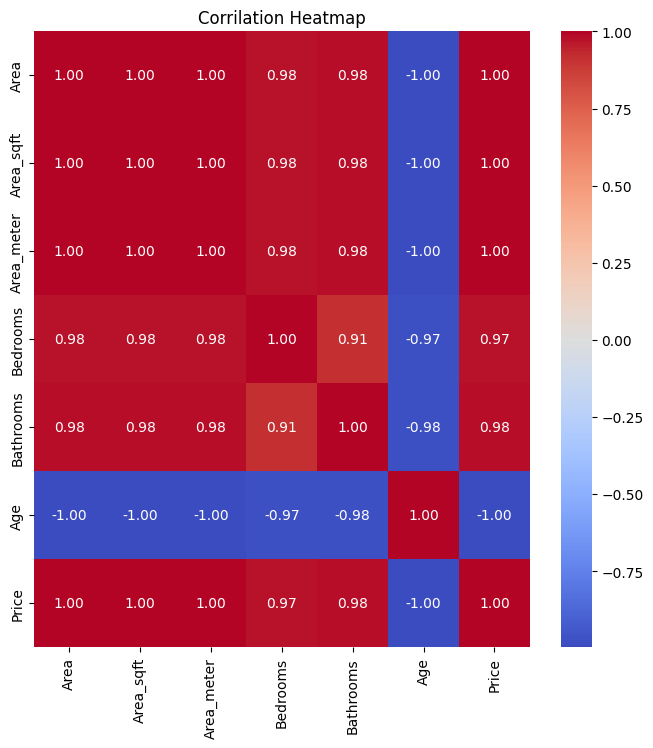

In [9]:
plt.figure(figsize=(8,8))

sns.heatmap(
    matrix,
    annot=True,
    cmap='coolwarm',
    fmt = ".2f"
)

plt.title("Corrilation Heatmap")
plt.show()

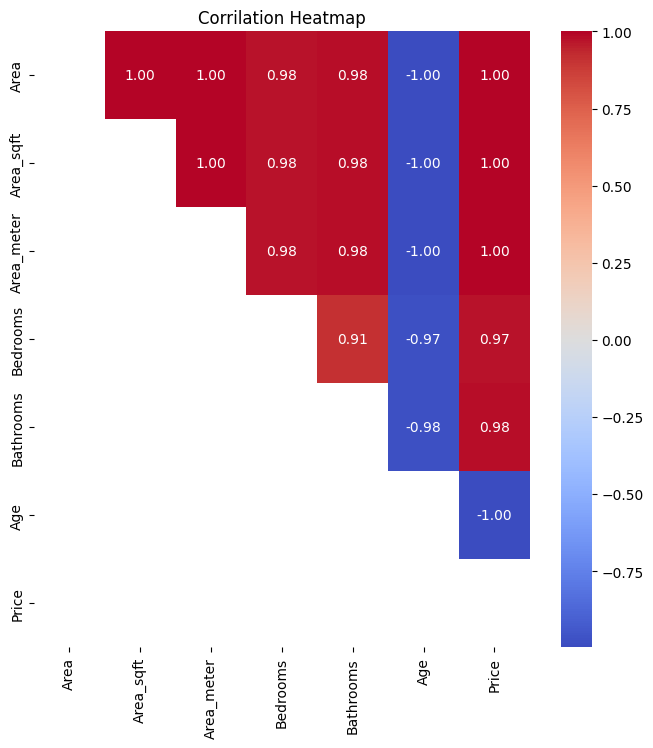

In [10]:
plt.figure(figsize=(8,8))

sns.heatmap(
    upper_trangle_matrix,
    annot=True,
    cmap='coolwarm',
    fmt = ".2f"
)

plt.title("Corrilation Heatmap")
plt.show()

In [11]:
to_drop = [
    column
    for column in upper_trangle_matrix.columns
    if any(upper_trangle_matrix[column] > 0.95)
]


to_drop

['Area_sqft', 'Area_meter', 'Bedrooms', 'Bathrooms', 'Price']

In [12]:
df

,Area,Area_sqft,Area_meter,Bedrooms,Bathrooms,Age,Price
0,1000,1000,92.9,2,1,15,50
1,1200,1200,111.5,2,2,14,60
2,1400,1400,130.1,3,2,12,70
3,1600,1600,148.6,3,3,10,82
4,1800,1800,167.2,4,3,8,95
5,2000,2000,185.8,4,4,6,108
6,2200,2200,204.4,5,4,5,120
7,2400,2400,223.0,5,5,3,135


In [20]:
df.drop(columns=["Area_meter","Bedrooms","Bathrooms"], inplace=True)
df


,Area,Age,Price
0,1000,15,50
1,1200,14,60
2,1400,12,70
3,1600,10,82
4,1800,8,95
5,2000,6,108
6,2200,5,120
7,2400,3,135


In [ ]:
##==========================================================New Operation===============================================================

In [22]:
import pandas as pd

df = pd.DataFrame({
    "Area": [900, 1100, 1300, 1500, 1700, 1900, 2100, 2300, 2500, 2700],

    "Area_sqft": [898, 1105, 1295, 1498, 1702, 1897, 2105, 2298, 2503, 2696],

    "Bedrooms": [2, 2, 3, 3, 3, 4, 4, 4, 5, 5],

    "Bathrooms": [1, 2, 2, 2, 3, 3, 3, 4, 4, 4],

    "Age": [25, 20, 18, 15, 12, 10, 8, 6, 4, 2],

    "Parking": [1, 1, 2, 2, 2, 3, 3, 2, 3, 4],

    "Distance_from_City": [18, 16, 14, 13, 11, 10, 8, 7, 5, 4],

    "Price": [42, 50, 58, 67, 76, 88, 101, 113, 128, 145]
})

df

,Area,Area_sqft,Bedrooms,Bathrooms,Age,Parking,Distance_from_City,Price
0,900,898,2,1,25,1,18,42
1,1100,1105,2,2,20,1,16,50
2,1300,1295,3,2,18,2,14,58
3,1500,1498,3,2,15,2,13,67
4,1700,1702,3,3,12,2,11,76
5,1900,1897,4,3,10,3,10,88
6,2100,2105,4,3,8,3,8,101
7,2300,2298,4,4,6,2,7,113
8,2500,2503,5,4,4,3,5,128
9,2700,2696,5,4,2,4,4,145


In [23]:
df.head()

,Area,Area_sqft,Bedrooms,Bathrooms,Age,Parking,Distance_from_City,Price
0,900,898,2,1,25,1,18,42
1,1100,1105,2,2,20,1,16,50
2,1300,1295,3,2,18,2,14,58
3,1500,1498,3,2,15,2,13,67
4,1700,1702,3,3,12,2,11,76


In [24]:
df.tail()

,Area,Area_sqft,Bedrooms,Bathrooms,Age,Parking,Distance_from_City,Price
5,1900,1897,4,3,10,3,10,88
6,2100,2105,4,3,8,3,8,101
7,2300,2298,4,4,6,2,7,113
8,2500,2503,5,4,4,3,5,128
9,2700,2696,5,4,2,4,4,145


In [25]:
df.describe()

,Area,Area_sqft,Bedrooms,Bathrooms,Age,Parking,Distance_from_City,Price
count,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000
mean,1800.000000,1799.700000,3.500000,2.800000,12.000000,2.300000,10.600000,86.800000
std,605.530071,605.523107,1.080123,1.032796,7.438638,0.948683,4.671426,34.437705
min,900.000000,898.000000,2.000000,1.000000,2.000000,1.000000,4.000000,42.000000
25%,1350.000000,1345.750000,3.000000,2.000000,6.500000,2.000000,7.250000,60.250000
50%,1800.000000,1799.500000,3.500000,3.000000,11.000000,2.000000,10.500000,82.000000
75%,2250.000000,2249.750000,4.000000,3.750000,17.250000,3.000000,13.750000,110.000000
max,2700.000000,2696.000000,5.000000,4.000000,25.000000,4.000000,18.000000,145.000000


In [26]:
corrilation_matrix = df.corr(numeric_only=True)
corrilation_matrix

,Area,Area_sqft,Bedrooms,Bathrooms,Age,Parking,Distance_from_City,Price
Area,1.000000,0.999981,0.968330,0.959403,-0.991641,0.870388,-0.997714,0.992127
Area_sqft,0.999981,1.000000,0.967746,0.959841,-0.991850,0.869412,-0.997851,0.991997
Bedrooms,0.968330,0.967746,1.000000,0.896421,-0.954201,0.921683,-0.968919,0.961846
Bathrooms,0.959403,0.959841,0.896421,1.000000,-0.969002,0.748455,-0.962653,0.939070
Age,-0.991641,-0.991850,-0.954201,-0.969002,1.000000,-0.865975,0.994432,-0.970277
Parking,0.870388,0.869412,0.921683,0.748455,-0.865975,1.000000,-0.872501,0.865885
Distance_from_City,-0.997714,-0.997851,-0.968919,-0.962653,0.994432,-0.872501,1.000000,-0.985455
Price,0.992127,0.991997,0.961846,0.939070,-0.970277,0.865885,-0.985455,1.000000


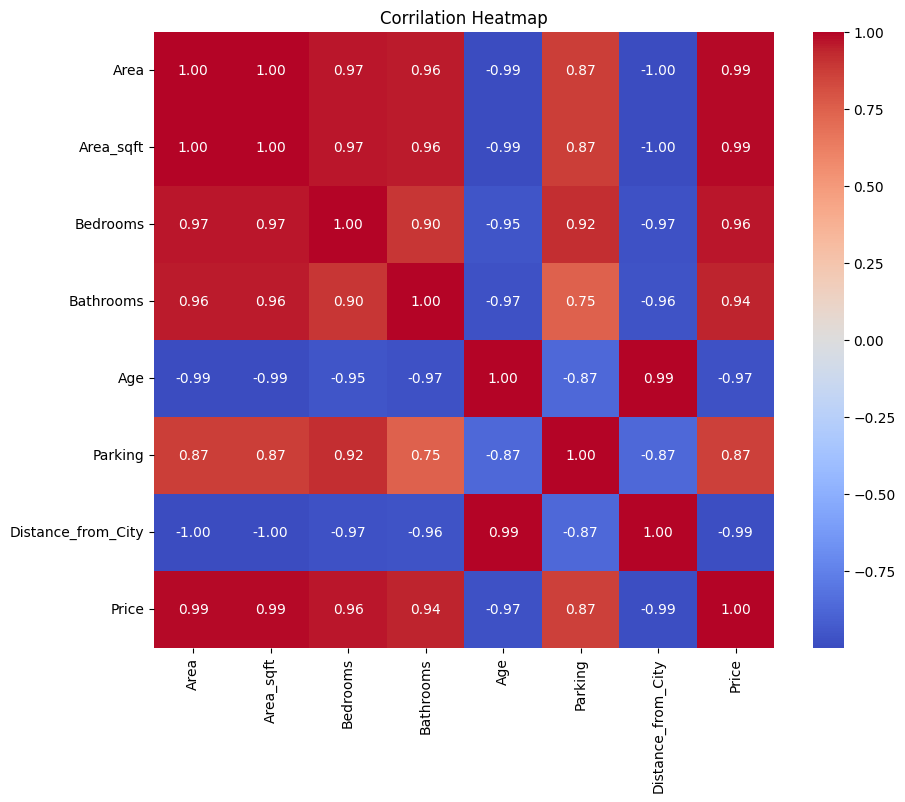

In [27]:
plt.figure(figsize=(10,8))

sns.heatmap(
    corrilation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt = ".2f"
    
    
)
plt.title("Corrilation Heatmap")
plt.show()

In [29]:
upper_trangle = corrilation_matrix.where(
    np.triu(np.ones(corrilation_matrix.shape),k=1).astype(bool)
)

upper_trangle

,Area,Area_sqft,Bedrooms,Bathrooms,Age,Parking,Distance_from_City,Price
Area,NaN,0.999981,0.968330,0.959403,-0.991641,0.870388,-0.997714,0.992127
Area_sqft,NaN,NaN,0.967746,0.959841,-0.991850,0.869412,-0.997851,0.991997
Bedrooms,NaN,NaN,NaN,0.896421,-0.954201,0.921683,-0.968919,0.961846
Bathrooms,NaN,NaN,NaN,NaN,-0.969002,0.748455,-0.962653,0.939070
Age,NaN,NaN,NaN,NaN,NaN,-0.865975,0.994432,-0.970277
Parking,NaN,NaN,NaN,NaN,NaN,NaN,-0.872501,0.865885
Distance_from_City,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.985455
Price,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [30]:
to_drop = [
    column
    for column in upper_trangle.columns
    if any(upper_trangle[column] > 0.95)
]


to_drop

['Area_sqft', 'Bedrooms', 'Bathrooms', 'Distance_from_City', 'Price']

In [39]:
final_dataset = df.drop(columns=["Area_sqft","Bedrooms","Bathrooms","Distance_from_City"])

final_dataset

KeyError: "['Area_sqft', 'Bedrooms', 'Bathrooms', 'Distance_from_City'] not found in axis"

In [42]:
df

,Area,Age,Parking,Price
0,900,25,1,42
1,1100,20,1,50
2,1300,18,2,58
3,1500,15,2,67
4,1700,12,2,76
5,1900,10,3,88
6,2100,8,3,101
7,2300,6,2,113
8,2500,4,3,128
9,2700,2,4,145


In [ ]:
##=======================================================================================================================================

In [44]:
import pandas as pd

df1 = pd.DataFrame({
    "Area": [1000,1200,1400,1600,1800,2000,2200,2400],
    "Area_sqft": [1005,1195,1402,1601,1804,1998,2203,2397],
    "Bedrooms": [2,2,3,3,4,4,5,5],
    "Bathrooms": [1,2,2,3,3,4,4,5],
    "Age": [20,18,15,12,10,8,6,4],
    "Parking": [1,1,2,2,2,3,3,3],
    "Price": [45,55,68,80,95,110,125,145]
})

df1

,Area,Area_sqft,Bedrooms,Bathrooms,Age,Parking,Price
0,1000,1005,2,1,20,1,45
1,1200,1195,2,2,18,1,55
2,1400,1402,3,2,15,2,68
3,1600,1601,3,3,12,2,80
4,1800,1804,4,3,10,2,95
5,2000,1998,4,4,8,3,110
6,2200,2203,5,4,6,3,125
7,2400,2397,5,5,4,3,145


In [46]:
df1.head()

,Area,Area_sqft,Bedrooms,Bathrooms,Age,Parking,Price
0,1000,1005,2,1,20,1,45
1,1200,1195,2,2,18,1,55
2,1400,1402,3,2,15,2,68
3,1600,1601,3,3,12,2,80
4,1800,1804,4,3,10,2,95


In [47]:
df1.tail()

,Area,Area_sqft,Bedrooms,Bathrooms,Age,Parking,Price
3,1600,1601,3,3,12,2,80
4,1800,1804,4,3,10,2,95
5,2000,1998,4,4,8,3,110
6,2200,2203,5,4,6,3,125
7,2400,2397,5,5,4,3,145


In [48]:
df1.describe()

,Area,Area_sqft,Bedrooms,Bathrooms,Age,Parking,Price
count,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000
mean,1700.000000,1700.625000,3.500000,3.000000,11.625000,2.125000,90.375000
std,489.897949,489.181514,1.195229,1.309307,5.705574,0.834523,34.862741
min,1000.000000,1005.000000,2.000000,1.000000,4.000000,1.000000,45.000000
25%,1350.000000,1350.250000,2.750000,2.000000,7.500000,1.750000,64.750000
50%,1700.000000,1702.500000,3.500000,3.000000,11.000000,2.000000,87.500000
75%,2050.000000,2049.250000,4.250000,4.000000,15.750000,3.000000,113.750000
max,2400.000000,2397.000000,5.000000,5.000000,20.000000,3.000000,145.000000


In [50]:
corrilation_matrix = df.corr(numeric_only=True)
corrilation_matrix

,Area,Age,Parking,Price
Area,1.000000,-0.991641,0.870388,0.992127
Age,-0.991641,1.000000,-0.865975,-0.970277
Parking,0.870388,-0.865975,1.000000,0.865885
Price,0.992127,-0.970277,0.865885,1.000000


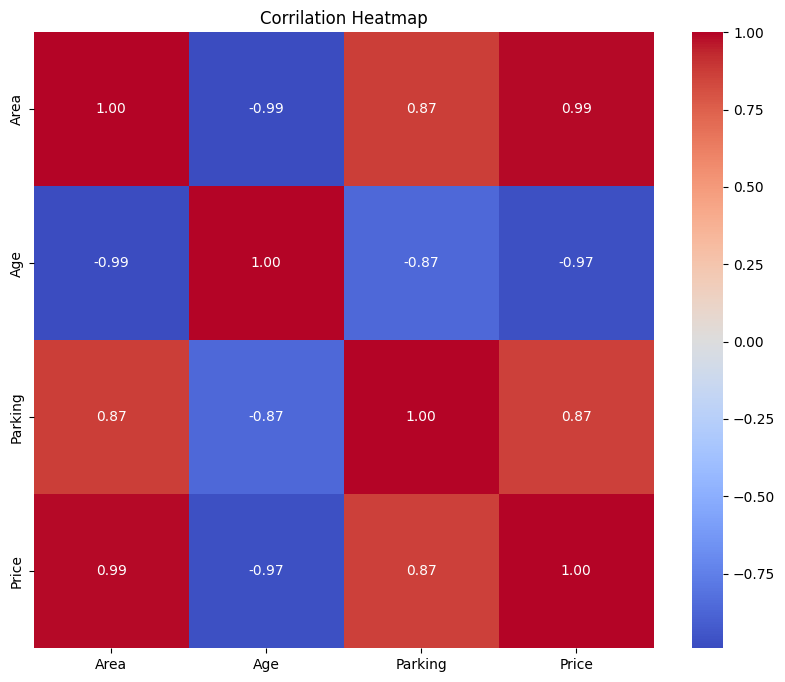

In [55]:
plt.figure(figsize=(10,8))

sns.heatmap(
    corrilation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt = ".2f"
    
    
)
plt.title("Corrilation Heatmap")
plt.show()

In [56]:
upper_trangle_matrix = corrilation_matrix.where(
    np.triu(np.ones(corrilation_matrix.shape),k=1).astype(bool)
)

upper_trangle_matrix

,Area,Age,Parking,Price
Area,NaN,-0.991641,0.870388,0.992127
Age,NaN,NaN,-0.865975,-0.970277
Parking,NaN,NaN,NaN,0.865885
Price,NaN,NaN,NaN,NaN


In [57]:
drop_values = [
    columns
    for columns in upper_trangle_matrix.columns
    if any(upper_trangle_matrix[columns]>95)
]
drop_values

[]

In [ ]:
#===============================================================================================================================================

In [58]:
df2 = pd.DataFrame({
    "Engine_CC": [800,1000,1200,1400,1600,1800,2000,2200],
    "HorsePower": [52,68,82,95,108,122,138,150],
    "Weight": [750,820,910,980,1100,1180,1260,1350],
    "Mileage": [24,22,20,18,17,16,15,14],
    "TopSpeed": [120,135,150,165,175,185,195,205],
    "FuelTank": [30,35,35,40,45,45,50,55],
    "Price": [4,5,6,8,10,12,15,18]
})

df2

,Engine_CC,HorsePower,Weight,Mileage,TopSpeed,FuelTank,Price
0,800,52,750,24,120,30,4
1,1000,68,820,22,135,35,5
2,1200,82,910,20,150,35,6
3,1400,95,980,18,165,40,8
4,1600,108,1100,17,175,45,10
5,1800,122,1180,16,185,45,12
6,2000,138,1260,15,195,50,15
7,2200,150,1350,14,205,55,18


In [59]:
df2.head()

,Engine_CC,HorsePower,Weight,Mileage,TopSpeed,FuelTank,Price
0,800,52,750,24,120,30,4
1,1000,68,820,22,135,35,5
2,1200,82,910,20,150,35,6
3,1400,95,980,18,165,40,8
4,1600,108,1100,17,175,45,10


In [60]:
df2.tail()

,Engine_CC,HorsePower,Weight,Mileage,TopSpeed,FuelTank,Price
3,1400,95,980,18,165,40,8
4,1600,108,1100,17,175,45,10
5,1800,122,1180,16,185,45,12
6,2000,138,1260,15,195,50,15
7,2200,150,1350,14,205,55,18


In [61]:
corrilation_matrix = df.corr(numeric_only=True)
corrilation_matrix

,Area,Age,Parking,Price
Area,1.000000,-0.991641,0.870388,0.992127
Age,-0.991641,1.000000,-0.865975,-0.970277
Parking,0.870388,-0.865975,1.000000,0.865885
Price,0.992127,-0.970277,0.865885,1.000000


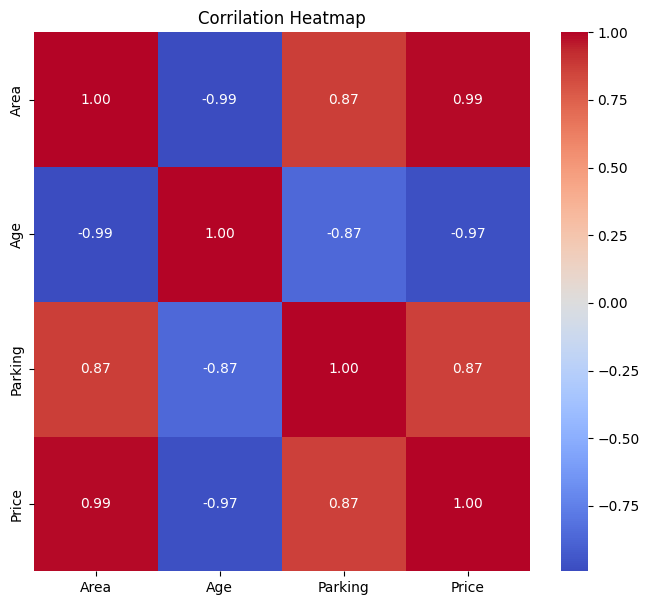

In [62]:
plt.figure(figsize=(8,7))

sns.heatmap(
    corrilation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt = ".2f"
    
)

plt.title("Corrilation Heatmap")
plt.show()

In [63]:
upper_trangle_matrix = corrilation_matrix.where(
    np.triu(np.ones(corrilation_matrix.shape),k=1).astype(bool)
)

upper_trangle_matrix

,Area,Age,Parking,Price
Area,NaN,-0.991641,0.870388,0.992127
Age,NaN,NaN,-0.865975,-0.970277
Parking,NaN,NaN,NaN,0.865885
Price,NaN,NaN,NaN,NaN


In [64]:
to_drop = [
    columns
    for columns in upper_trangle_matrix.columns
    if any(upper_trangle_matrix[columns]>0.95)
]

to_drop

['Price']

In [ ]:
#========================================================================================================================================

In [65]:
df3 = pd.DataFrame({
    "Study_Hours": [2,3,4,5,6,7,8,9],
    "Attendance": [60,65,72,78,85,90,95,98],
    "Assignments": [4,5,6,7,8,9,10,10],
    "Sleep_Hours": [8,7,7,6,6,6,5,5],
    "Mobile_Hours": [6,5,5,4,4,3,2,2],
    "Marks": [45,55,65,72,82,88,94,98]
})

df3

,Study_Hours,Attendance,Assignments,Sleep_Hours,Mobile_Hours,Marks
0,2,60,4,8,6,45
1,3,65,5,7,5,55
2,4,72,6,7,5,65
3,5,78,7,6,4,72
4,6,85,8,6,4,82
5,7,90,9,6,3,88
6,8,95,10,5,2,94
7,9,98,10,5,2,98


In [66]:
df3.head()

,Study_Hours,Attendance,Assignments,Sleep_Hours,Mobile_Hours,Marks
0,2,60,4,8,6,45
1,3,65,5,7,5,55
2,4,72,6,7,5,65
3,5,78,7,6,4,72
4,6,85,8,6,4,82


In [67]:
df3.tail()

,Study_Hours,Attendance,Assignments,Sleep_Hours,Mobile_Hours,Marks
3,5,78,7,6,4,72
4,6,85,8,6,4,82
5,7,90,9,6,3,88
6,8,95,10,5,2,94
7,9,98,10,5,2,98


In [68]:
df3.describe()

,Study_Hours,Attendance,Assignments,Sleep_Hours,Mobile_Hours,Marks
count,8.00000,8.000000,8.000000,8.000000,8.000000,8.000000
mean,5.50000,80.375000,7.375000,6.250000,3.875000,74.875000
std,2.44949,13.968715,2.263846,1.035098,1.457738,18.961898
min,2.00000,60.000000,4.000000,5.000000,2.000000,45.000000
25%,3.75000,70.250000,5.750000,5.750000,2.750000,62.500000
50%,5.50000,81.500000,7.500000,6.000000,4.000000,77.000000
75%,7.25000,91.250000,9.250000,7.000000,5.000000,89.500000
max,9.00000,98.000000,10.000000,8.000000,6.000000,98.000000


In [73]:
corrilation_matrix = df3.corr(numeric_only=True)

corrilation_matrix

,Study_Hours,Attendance,Assignments,Sleep_Hours,Mobile_Hours,Marks
Study_Hours,1.000000,0.995768,0.991837,-0.957841,-0.980196,0.991915
Attendance,0.995768,1.000000,0.997804,-0.955905,-0.972540,0.997984
Assignments,0.991837,0.997804,1.000000,-0.960183,-0.979409,0.996297
Sleep_Hours,-0.957841,-0.955905,-0.960183,1.000000,0.970431,-0.958935
Mobile_Hours,-0.980196,-0.972540,-0.979409,0.970431,1.000000,-0.967102
Marks,0.991915,0.997984,0.996297,-0.958935,-0.967102,1.000000


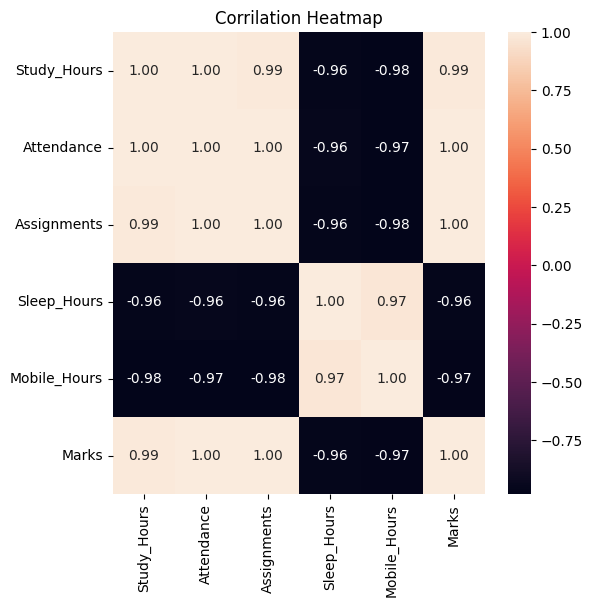

In [74]:
plt.figure(figsize=(6,6))

sns.heatmap(
    corrilation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title("Corrilation Heatmap")
plt.show()

In [75]:
upper_trangle = corrilation_matrix.where(
    np.triu(np.ones(corrilation_matrix.shape).astype(bool))
)

upper_trangle

,Study_Hours,Attendance,Assignments,Sleep_Hours,Mobile_Hours,Marks
Study_Hours,1.0,0.995768,0.991837,-0.957841,-0.980196,0.991915
Attendance,NaN,1.000000,0.997804,-0.955905,-0.972540,0.997984
Assignments,NaN,NaN,1.000000,-0.960183,-0.979409,0.996297
Sleep_Hours,NaN,NaN,NaN,1.000000,0.970431,-0.958935
Mobile_Hours,NaN,NaN,NaN,NaN,1.000000,-0.967102
Marks,NaN,NaN,NaN,NaN,NaN,1.000000


In [76]:
to_drop = [
    columns
    for columns in upper_trangle
    if any(upper_trangle[columns]>0.95)
]

to_drop


['Study_Hours',
 'Attendance',
 'Assignments',
 'Sleep_Hours',
 'Mobile_Hours',
 'Marks']

In [78]:
new_feature = df3.drop(columns=["Study_Hours","Attendance","Assignments","Sleep_Hours","Mobile_Hours"])

new_feature

,Marks
0,45
1,55
2,65
3,72
4,82
5,88
6,94
7,98


In [81]:
print("="*150)

In [82]:
df4 = pd.DataFrame({
    "Height": [150,155,160,165,170,175,180,185],
    "Weight": [45,50,56,63,70,78,85,92],
    "BMI": [20,20.8,21.9,23.1,24.2,25.5,26.2,26.9],
    "Age": [18,22,25,30,35,40,45,50],
    "Exercise": [5,5,4,4,3,3,2,2],
    "Calories": [1800,1900,2000,2150,2300,2450,2600,2750]
})

df4

,Height,Weight,BMI,Age,Exercise,Calories
0,150,45,20.0,18,5,1800
1,155,50,20.8,22,5,1900
2,160,56,21.9,25,4,2000
3,165,63,23.1,30,4,2150
4,170,70,24.2,35,3,2300
5,175,78,25.5,40,3,2450
6,180,85,26.2,45,2,2600
7,185,92,26.9,50,2,2750


In [83]:
df4.head()

,Height,Weight,BMI,Age,Exercise,Calories
0,150,45,20.0,18,5,1800
1,155,50,20.8,22,5,1900
2,160,56,21.9,25,4,2000
3,165,63,23.1,30,4,2150
4,170,70,24.2,35,3,2300


In [84]:
df4.tail()

,Height,Weight,BMI,Age,Exercise,Calories
3,165,63,23.1,30,4,2150
4,170,70,24.2,35,3,2300
5,175,78,25.5,40,3,2450
6,180,85,26.2,45,2,2600
7,185,92,26.9,50,2,2750


In [85]:
df4.describe()

,Height,Weight,BMI,Age,Exercise,Calories
count,8.000000,8.00000,8.00000,8.000000,8.000000,8.000000
mean,167.500000,67.37500,23.57500,33.125000,3.500000,2243.750000
std,12.247449,16.85177,2.55105,11.369602,1.195229,340.627048
min,150.000000,45.00000,20.00000,18.000000,2.000000,1800.000000
25%,158.750000,54.50000,21.62500,24.250000,2.750000,1975.000000
50%,167.500000,66.50000,23.65000,32.500000,3.500000,2225.000000
75%,176.250000,79.75000,25.67500,41.250000,4.250000,2487.500000
max,185.000000,92.00000,26.90000,50.000000,5.000000,2750.000000


In [86]:
corrilation_matrix = df4.corr(numeric_only=True)

corrilation_matrix

,Height,Weight,BMI,Age,Exercise,Calories
Height,1.000000,0.998451,0.996767,0.997702,-0.975900,0.997340
Weight,0.998451,1.000000,0.995504,0.999582,-0.975232,0.999691
BMI,0.996767,0.995504,1.000000,0.993568,-0.974530,0.993597
Age,0.997702,0.999582,0.993568,1.000000,-0.972406,0.999878
Exercise,-0.975900,-0.975232,-0.974530,-0.972406,1.000000,-0.973722
Calories,0.997340,0.999691,0.993597,0.999878,-0.973722,1.000000


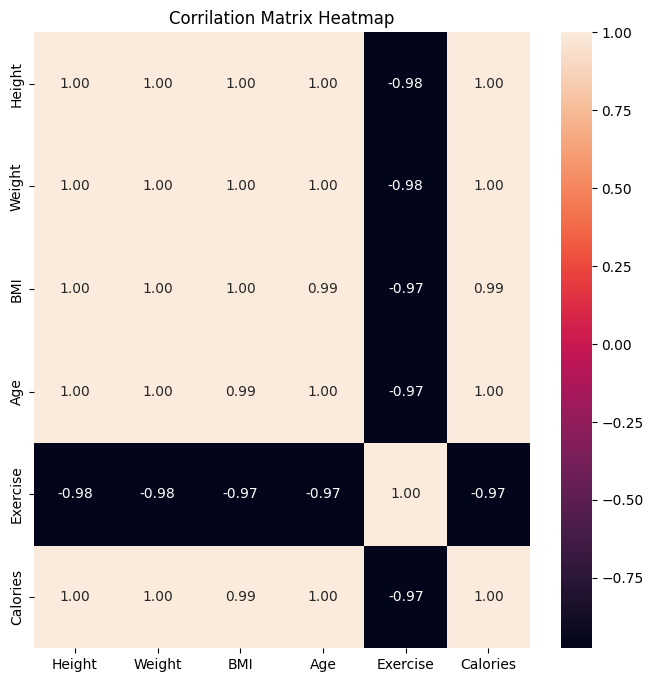

In [87]:
plt.figure(figsize=(8,8))

sns.heatmap(
    corrilation_matrix,
    annot=True,
    fmt = ".2f"
)

plt.title("Corrilation Matrix Heatmap")

plt.show()

In [88]:
upper_trangle = corrilation_matrix.where(
    np.triu(np.ones(corrilation_matrix.shape),k=1).astype(bool)
)

upper_trangle

,Height,Weight,BMI,Age,Exercise,Calories
Height,NaN,0.998451,0.996767,0.997702,-0.975900,0.997340
Weight,NaN,NaN,0.995504,0.999582,-0.975232,0.999691
BMI,NaN,NaN,NaN,0.993568,-0.974530,0.993597
Age,NaN,NaN,NaN,NaN,-0.972406,0.999878
Exercise,NaN,NaN,NaN,NaN,NaN,-0.973722
Calories,NaN,NaN,NaN,NaN,NaN,NaN


In [89]:
drop_values = [
    columns
    for columns in upper_trangle
    if any(upper_trangle[columns]>0.95)
]

drop_values


['Weight', 'BMI', 'Age', 'Calories']

In [92]:
df4 = df4.drop(columns = ["Weight","BMI","Age","Calories"])

df4

,Height,Exercise
0,150,5
1,155,5
2,160,4
3,165,4
4,170,3
5,175,3
6,180,2
7,185,2


In [93]:
df4

,Height,Exercise
0,150,5
1,155,5
2,160,4
3,165,4
4,170,3
5,175,3
6,180,2
7,185,2


In [94]:
print("="*150)

In [95]:
df5 = pd.DataFrame({
    "Items": [1,2,3,4,5,6,7,8],
    "Cart_Value": [200,450,700,900,1200,1450,1700,2000],
    "Discount": [5,5,10,10,15,15,20,20],
    "Delivery_Time": [5,5,4,4,3,3,2,2],
    "Customer_Age": [19,24,28,31,35,40,45,50],
    "Rating": [3.5,3.8,4.0,4.2,4.3,4.5,4.7,4.8]
})

df5

,Items,Cart_Value,Discount,Delivery_Time,Customer_Age,Rating
0,1,200,5,5,19,3.5
1,2,450,5,5,24,3.8
2,3,700,10,4,28,4.0
3,4,900,10,4,31,4.2
4,5,1200,15,3,35,4.3
5,6,1450,15,3,40,4.5
6,7,1700,20,2,45,4.7
7,8,2000,20,2,50,4.8


In [96]:
df5.head(
    
)

,Items,Cart_Value,Discount,Delivery_Time,Customer_Age,Rating
0,1,200,5,5,19,3.5
1,2,450,5,5,24,3.8
2,3,700,10,4,28,4.0
3,4,900,10,4,31,4.2
4,5,1200,15,3,35,4.3


In [98]:
df5.tail()

,Items,Cart_Value,Discount,Delivery_Time,Customer_Age,Rating
3,4,900,10,4,31,4.2
4,5,1200,15,3,35,4.3
5,6,1450,15,3,40,4.5
6,7,1700,20,2,45,4.7
7,8,2000,20,2,50,4.8


In [99]:
df5.describe(
    
)

,Items,Cart_Value,Discount,Delivery_Time,Customer_Age,Rating
count,8.00000,8.0000,8.000000,8.000000,8.000000,8.000000
mean,4.50000,1075.0000,12.500000,3.500000,34.000000,4.225000
std,2.44949,624.4998,5.976143,1.195229,10.583005,0.446414
min,1.00000,200.0000,5.000000,2.000000,19.000000,3.500000
25%,2.75000,637.5000,8.750000,2.750000,27.000000,3.950000
50%,4.50000,1050.0000,12.500000,3.500000,33.000000,4.250000
75%,6.25000,1512.5000,16.250000,4.250000,41.250000,4.550000
max,8.00000,2000.0000,20.000000,5.000000,50.000000,4.800000


In [100]:
corrilation_matrix = df5.corr(numeric_only=True)

corrilation_matrix

,Items,Cart_Value,Discount,Delivery_Time,Customer_Age,Rating
Items,1.000000,0.999258,0.975900,-0.975900,0.997461,0.992892
Cart_Value,0.999258,1.000000,0.976088,-0.976088,0.998625,0.988983
Discount,0.975900,0.976088,1.000000,-1.000000,0.971271,0.963863
Delivery_Time,-0.975900,-0.976088,-1.000000,1.000000,-0.971271,-0.963863
Customer_Age,0.997461,0.998625,0.971271,-0.971271,1.000000,0.988787
Rating,0.992892,0.988983,0.963863,-0.963863,0.988787,1.000000


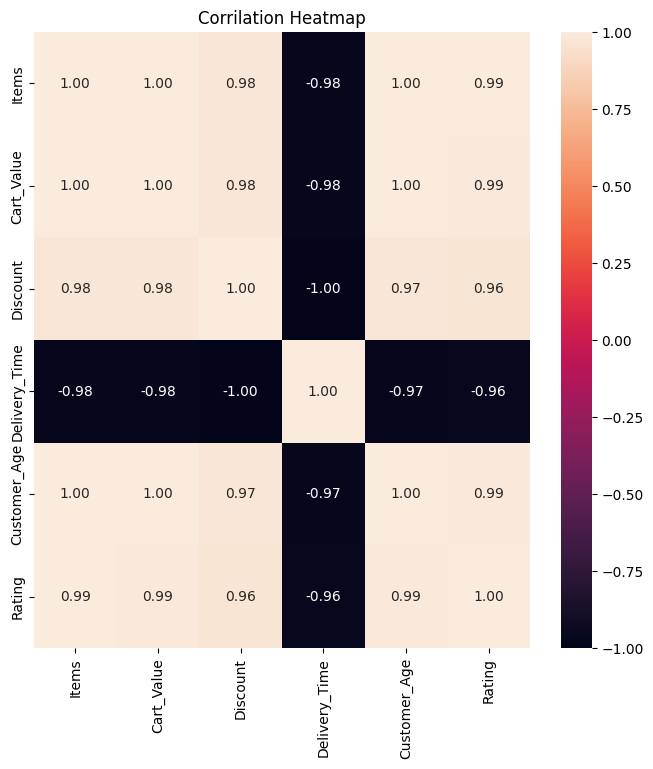

In [101]:
plt.figure(figsize=(8,8))

sns.heatmap(
    corrilation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title("Corrilation Heatmap")
plt.show()

In [103]:
upper_trangle = corrilation_matrix.where(
    np.triu(np.ones(corrilation_matrix.shape),k=1).astype(bool)
)

upper_trangle


,Items,Cart_Value,Discount,Delivery_Time,Customer_Age,Rating
Items,NaN,0.999258,0.975900,-0.975900,0.997461,0.992892
Cart_Value,NaN,NaN,0.976088,-0.976088,0.998625,0.988983
Discount,NaN,NaN,NaN,-1.000000,0.971271,0.963863
Delivery_Time,NaN,NaN,NaN,NaN,-0.971271,-0.963863
Customer_Age,NaN,NaN,NaN,NaN,NaN,0.988787
Rating,NaN,NaN,NaN,NaN,NaN,NaN


In [104]:
droped_value = [
    columns
    for columns in corrilation_matrix
    if any(corrilation_matrix[columns]>0.95)
]

droped_value

['Items', 'Cart_Value', 'Discount', 'Delivery_Time', 'Customer_Age', 'Rating']